# EDA

## Imports 

In [3]:


import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

# warnings.filterwarnings('ignore')

## Load file (data)

In [4]:


data = pd.read_csv('insurance.csv')   # it returns the object of <class 'pandas.DataFrame'>
print(type(data))


<class 'pandas.DataFrame'>


## Viewing 

In [5]:


data.shape    # It shows the no. of rows and columns 

(1338, 7)

In [6]:
data.head()   # Only shows the top 5 data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


## Summary Statistics

In [9]:


data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
data.mode()

,age,sex,bmi,children,smoker,region,charges
0,18,male,32.3,0,no,southeast,1639.5631


## Value count

In [11]:
data['region'].value_counts()       # it shows, how many unique values are there and how many times they appeared

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [12]:
data['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

## Null (missing) value analysis

In [13]:
data.isnull().sum()


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [14]:
(data.isnull().sum()/len(data))*100

age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
charges     0.0
dtype: float64

## Visualization

In [15]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [16]:
 numeric_columns = ['age', 'bmi', 'children', 'charges']

### Histogram (to shows distribution of data)

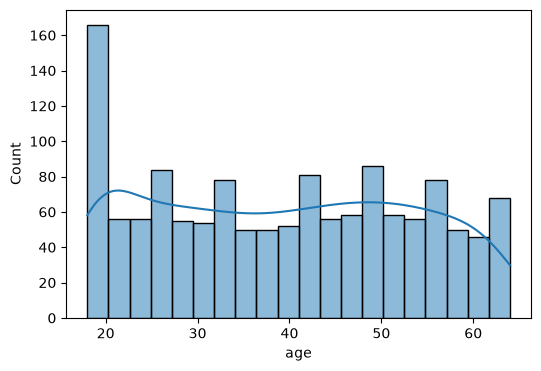

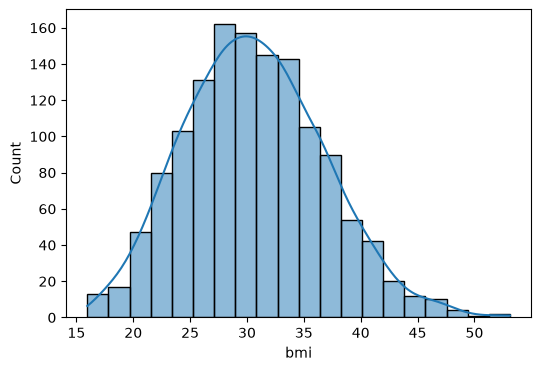

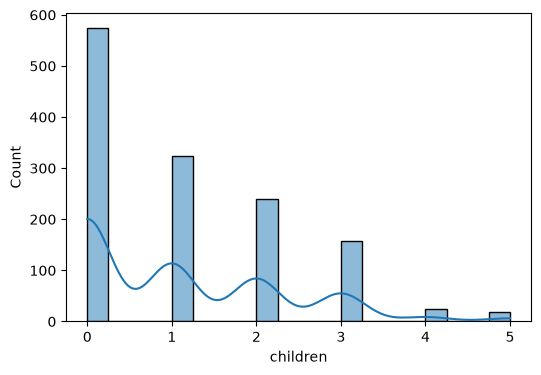

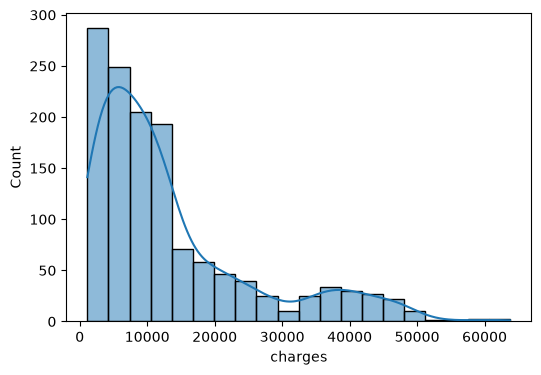

In [17]:
for col in numeric_columns:
    plt.figure(figsize = (6,4))
    sb.histplot(data[col], kde=True, bins=20)

### Barplot (using countplot)

<Axes: xlabel='children', ylabel='count'>

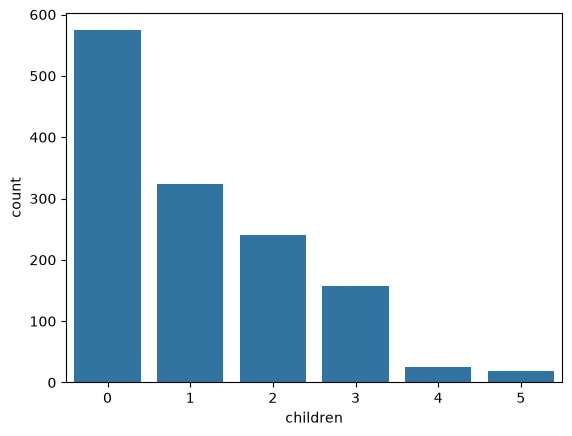

In [18]:
sb.countplot(x=data['children'])

<Axes: xlabel='smoker', ylabel='count'>

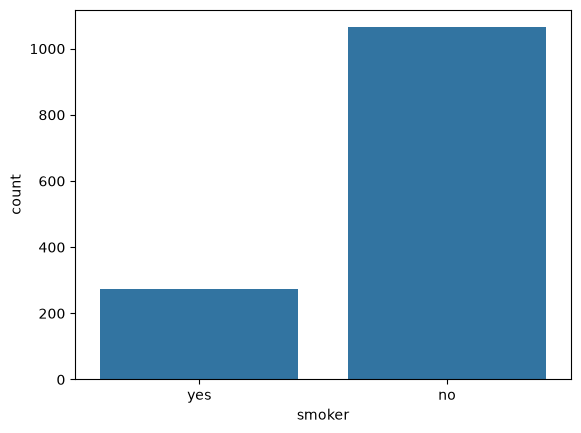

In [19]:
sb.countplot(x=data['smoker'])

<Axes: xlabel='region', ylabel='count'>

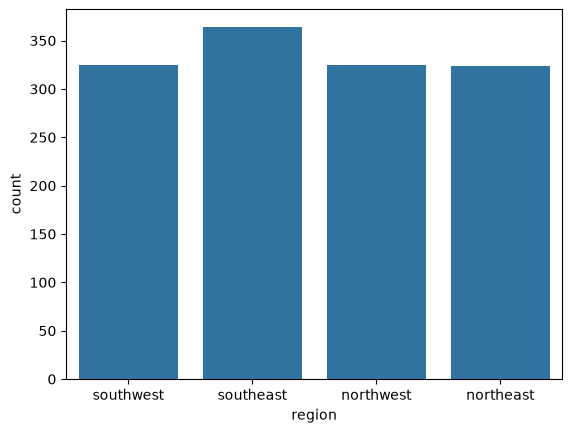

In [20]:
sb.countplot(x = data['region'])

<Axes: xlabel='sex', ylabel='count'>

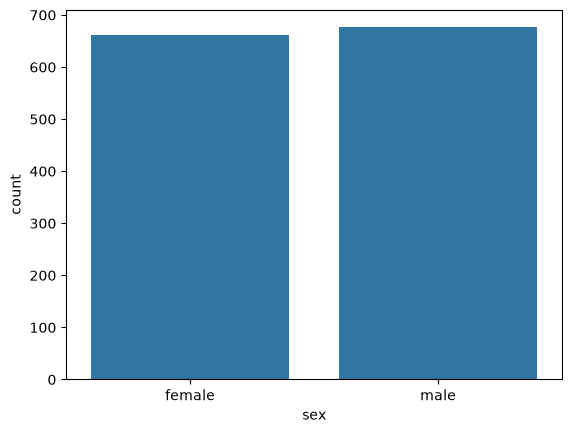

In [21]:
sb.countplot(x=data['sex'])

### Boxplot (to see the outliers)

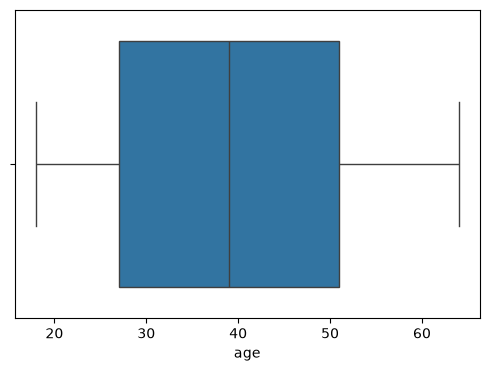

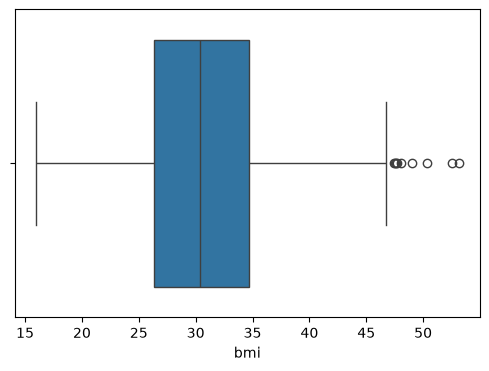

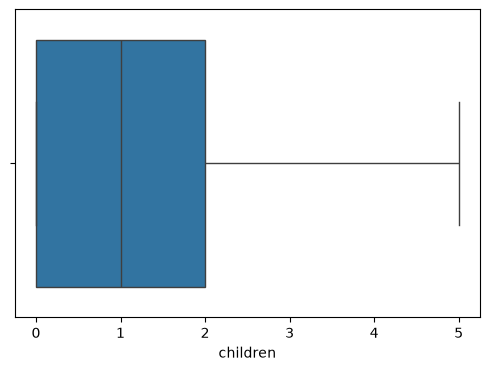

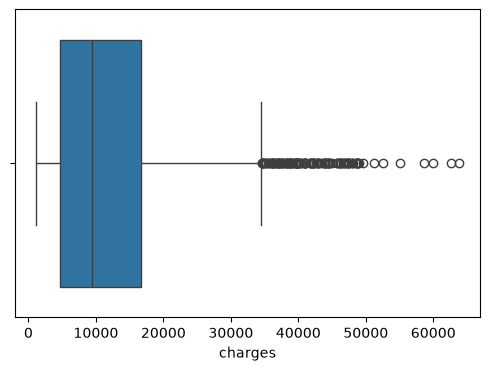

In [22]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sb.boxplot(x = data[col])
    plt.show()

### Heatmap (to see correlation )

<Axes: >

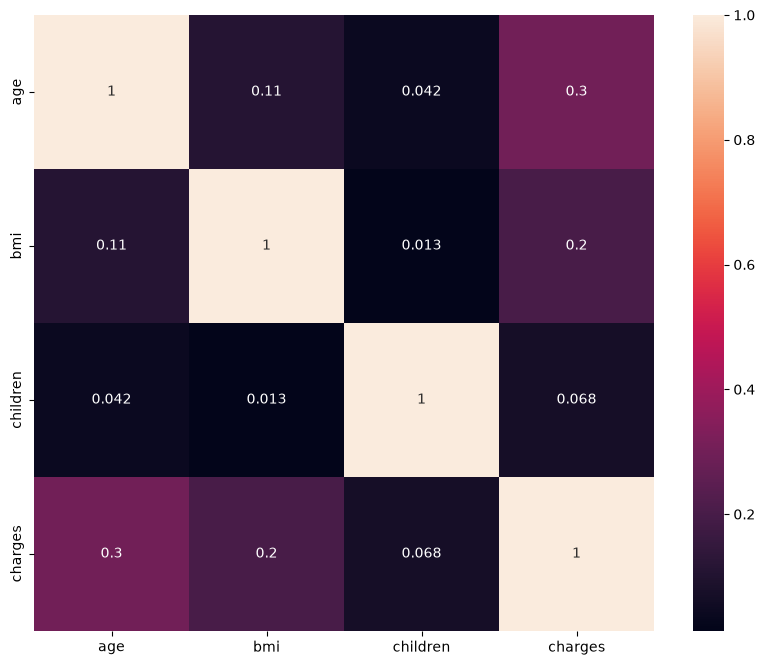

In [23]:
plt.figure(figsize=(10, 8))
sb.heatmap(data.corr(numeric_only=True), annot=True)

### Scatter plot

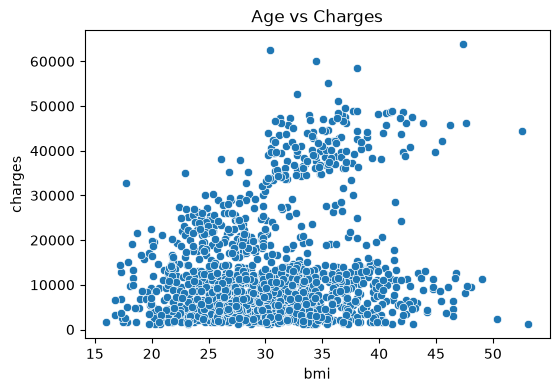

In [24]:
plt.figure(figsize=(6,4))
sb.scatterplot(x=data['bmi'], y=data['charges'])
plt.title("Age vs Charges")
plt.show()

# Data Cleaning and Preprocessing 

## Copy the existing data

In [25]:
data_cleaned = data.copy()

In [26]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Remove (handle) null values

In [27]:

data_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [28]:
# There is no null vlaues in this data 

## Remove duplicates 

In [29]:
data_cleaned.shape

(1338, 7)

In [30]:
data_cleaned.drop_duplicates(inplace = True)

In [31]:
data_cleaned.shape

(1337, 7)

##  Fixing datatypes

In [32]:
data_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 105.2 KB


In [33]:
data_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

## Label encoding

In [34]:
data_cleaned['sex'] = data_cleaned['sex'].map({"male":0, "female":1})

In [35]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [36]:
data_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [37]:
data_cleaned['smoker'] = data_cleaned['smoker'].map({"no":0, "yes":1})

In [38]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [39]:
# Remaning the columns 

data_cleaned.rename(columns={
    "sex":"is_female",
    "smoker":"is_smoker"
}, inplace=True)

In [40]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


## One-hot encoding 

In [41]:
data_cleaned = pd.get_dummies(data_cleaned, columns = ['region'])

In [42]:
data_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False


In [43]:
data_cleaned = data_cleaned.astype(int)

In [44]:
data_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


 # Feature engineering and extraction

<Axes: xlabel='bmi', ylabel='Count'>

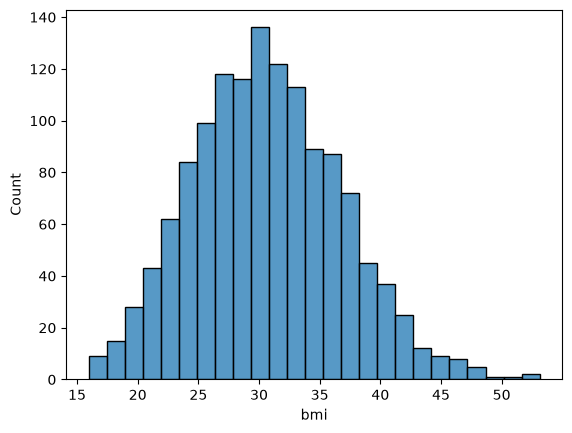

In [47]:
sb.histplot(data['bmi'])
